<a href="https://colab.research.google.com/github/harnalashok/hadoop/blob/main/fraud_detection_clustering_anomaly_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Last amended: 19th Oct, 2026
# My GitHub repo: Hadoop
# Refer: https://www.kaggle.com/code/sulaniishara/fraud-detection-clustering-anomaly-analysis?select=bank_transactions_data_2.csv

## Dataset Overview

This dataset contains transaction data intended for the analysis and detection of potential fraudulent activities. The data includes various attributes that provide insights into the transactional behavior, customer profiles, and other contextual details, making it suitable for applying different clustering and anomaly detection techniques.

### Key Features:
- **TransactionID:** A unique identifier for each transaction.
- **AccountID:** A unique identifier for the account associated with the transaction.
- **TransactionAmount:** The monetary value of each transaction, varying from small expenses to large purchases.
- **TransactionDate:** The date and time when the transaction occurred.
- **TransactionType:** Categorical value indicating whether the transaction was a 'Credit' or 'Debit'.
- **Location:** The geographic location where the transaction took place.
- **DeviceID:** A unique identifier for the device used to perform the transaction.
- **IP Address:** The IP address associated with the transaction.
- **MerchantID:** A unique identifier for merchants involved in the transaction.
- **Channel:** Indicates the channel through which the transaction was conducted (e.g., Online, ATM, Branch).
- **AccountBalance:** The balance remaining in the account after the transaction.
- **TransactionDuration:** Duration of the transaction in seconds.
- **LoginAttempts:** The number of login attempts made before the transaction.

### Objectives:
- **Fraud Detection:** Utilize clustering algorithms and anomaly detection techniques to identify potential fraudulent transactions.
- **Behavioral Insights:** Gain insights into transactional behavior patterns to understand normal vs. anomalous behavior.

## Imports and setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor

import warnings
warnings.filterwarnings("ignore")

In [2]:
from google.colab import drive
drive.mount('/gdrive')

Mounted at /gdrive


## Load and Explore dataset

In [3]:
# Load the dataset
dataPath = "/gdrive/MyDrive/bank_transaction/bank_transactions_data_2.csv"
df = pd.read_csv(dataPath)

# Display basic information about the dataset
print("Shape of the dataset:", df.shape)
display(df.head())

Shape of the dataset: (2512, 16)


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


In [ ]:
# Display basic information
print("Dataset Information:")
print(df.info())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  Acc

### Dataset Information

- **Dataset Size:** The dataset contains 2512 entries across 16 columns, providing a comprehensive view of transactional data.
- **Data Types:** The dataset includes a mix of numerical and categorical data types. Numerical columns (`float64`: `TransactionAmount`, `AccountBalance`; `int64`: `CustomerAge`, `TransactionDuration`, `LoginAttempts`) offer quantitative insights, while categorical columns (`object`: most other fields) provide contextual information.

### Key Observations

1.  **Categorical vs. Numerical Data:**
    - Most columns (11 out of 16) are categorical (`object` type), which can be useful for identifying patterns in transaction types, locations, devices, etc.
    - Numerical columns allow for statistical analysis and clustering based on transaction amounts and durations.

2.  **Missing Values:**
    - There are no missing values in the dataset as all columns have non-null counts equal to the total number of rows (2512).

3.  **Temporal Information:**
    - Both current and previous transaction dates are available (`TransactionDate` and `PreviousTransactionDate`), enabling analysis of temporal patterns or sequences in transactions.

4.  **Customer Information:**
    - Customer demographics like age (`CustomerAge`) and occupation (`CustomerOccupation`) can help identify behavioral trends specific to certain groups.

5.  **Security Features:**
    - Fields such as login attempts before transactions suggest that security measures or user behavior might be analyzed for potential fraud detection.

6.  **Geographic Distribution:**
    - Location data could reveal regional patterns or hotspots where fraudulent activities might occur more frequently.

In [ ]:
# For numerical statistics
numerical_stats = df.describe()
display(numerical_stats)



,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


**1. Statistical Insights**

*   **TransactionAmount:**
    *   **Mean:** 297.59. The average transaction amount is around 300.
    *   **Std:** 291.95.  There is a significant standard deviation, indicating a wide range of transaction amounts.
    *   **Min:** 0.27.  There are very small transactions in the dataset.
    *   **Max:** 1919.11.  The largest transaction is significantly higher than the mean, suggesting the presence of outliers or high-value transactions.
    *   **Insight:** The distribution of transaction amounts is likely skewed to the right (positive skew), meaning there are more small transactions than large ones. This is typical for transaction data.
*   **CustomerAge:**
    *   **Mean:** 44.67 years. The average age of customers is around 45.
    *   **Std:** 17.79 years. A reasonable standard deviation, suggesting a good mix of age groups.
    *   **Min:** 18 years. The youngest customer is 18 years old.
    *   **Max:** 80 years. The oldest customer is 80 years old.
    *   **Insight:** The customer base covers a broad age range, which could be useful for segmenting customers based on age and analyzing their transaction behavior.
*   **TransactionDuration:**
    *   **Mean:** 119.64 seconds. On average, transactions take about 2 minutes.
    *   **Std:** 69.96 seconds. There's a notable variation in transaction duration.
    *   **Min:** 10 seconds.
    *   **Max:** 300 seconds (5 minutes).
    *   **Insight:** Variations in transaction duration might be linked to the type of transaction, channel, or potential fraudulent activity. Longer durations might indicate more complex or suspicious transactions.
*   **LoginAttempts:**
    *   **Mean:** 1.12. On average, there are slightly more than 1 login attempt per transaction.
    *   **Std:** 0.60. The standard deviation is relatively low.
    *   **Min:** 1.
    *   **Max:** 5.
    *   **Insight:** The minimum number of login attempts is 1, which means every transaction involves at least one login attempt. The maximum of 5 attempts could be a flag for potential account compromise or suspicious activity. A higher number of login attempts might correlate with fraudulent transactions.
*   **AccountBalance:**
    *   **Mean:** \$5114.30. The average account balance is around \$5100.
    *   **Std:** \$3900.94. A high standard deviation indicates a significant range in account balances.
    *   **Min:** \$101.25. Some accounts have relatively low balances.
    *   **Max:** \$14977.99. Some accounts have very high balances.
    *   **Insight:** Account balances vary significantly, which could influence transaction patterns. Low-balance accounts might exhibit different transaction behaviors compared to high-balance accounts.

**2. Implications for Fraud Detection**

*   **Feature Importance:** The statistical summary highlights the importance of features such as `TransactionAmount`, `CustomerAge`, `TransactionDuration`, `LoginAttempts`, and `AccountBalance` in identifying potential fraudulent transactions.
*   **Anomaly Detection:** The presence of outliers in `TransactionAmount` and the range of `LoginAttempts` suggest that anomaly detection techniques could be effective in identifying fraudulent transactions.
*   **Segmentation:** The customer base can be segmented based on age, occupation, and account balance to analyze their transaction behavior and identify potential fraud patterns within specific segments.


In [ ]:
# Get categorical statistics
categorical_stats = df.describe(include='object').T

# Display the styled DataFrame
display(categorical_stats)

,count,unique,top,freq
TransactionID,2512,2512,TX002496,1
AccountID,2512,495,AC00460,12
TransactionDate,2512,2512,2023-04-03 16:07:53,1
TransactionType,2512,2,Debit,1944
Location,2512,43,Fort Worth,70
DeviceID,2512,681,D000548,9
IP Address,2512,592,200.136.146.93,13
MerchantID,2512,100,M026,45
Channel,2512,3,Branch,868
CustomerOccupation,2512,4,Student,657


#### Key Observation

**1. TransactionID:**

* **Unique for Each Transaction:** As expected, `TransactionID` is unique for every transaction, ensuring that each record represents a distinct event.

**2. AccountID:**

* **Multiple Transactions per Account:** 495 unique `AccountID` values within 2512 transactions indicate that some accounts have multiple transactions associated with them.
* **Most Frequent Account:** `AC00362` has the highest frequency with 12 transactions, suggesting potential patterns or anomalies related to this specific account.

**3. TransactionDate:**

* **Unique for Each Transaction:** Each transaction has a unique `TransactionDate` and `TransactionTime`, reflecting the temporal nature of the data. This will be valuable for time-series analysis and identifying potential temporal patterns in fraudulent activity.

**4. TransactionType:**

* **Dominated by Debit Transactions:** `Debit` transactions are significantly more frequent than `Credit` transactions, suggesting a potential imbalance in the dataset that might need to be addressed during model training.

**5. Location:**

* **Diverse Locations:** Transactions occurred in 43 different locations, indicating a geographically diverse customer base.
* **Most Frequent Location:** `Fort Worth` has the highest frequency with 70 transactions. This could be a significant location for analysis or may indicate a potential hotspot for fraudulent activity.

**6. DeviceID:**

* **Multiple Devices:** 681 unique `DeviceID` values suggest that transactions were conducted using a variety of devices.
* **Most Frequent Device:** `D000697` was used for 9 transactions, potentially indicating a frequent user or a device that might require closer scrutiny.

**7. IP Address:**

* **Diverse IP Addresses:** 592 unique IP addresses were used for transactions, reflecting the distributed nature of the data.
* **Most Frequent IP Address:** `200.136.146.93` was used for 13 transactions, which could indicate a specific user or location with high transaction activity.

**8. MerchantID:**

* **Multiple Merchants:** Transactions involved 100 different merchants, suggesting a diverse range of businesses.
* **Most Frequent Merchant:** `M026` has the highest frequency with 45 transactions, potentially indicating a popular merchant or a potential target for fraudulent activity.

**9. Channel:**

* **Multiple Transaction Channels:** Transactions were conducted through 3 different channels (e.g., Online, ATM, Branch), providing valuable information about customer behavior and potential vulnerabilities in different channels.

**10. CustomerOccupation:**

* **Diverse Occupations:** Customers represent 4 different occupations, offering potential insights into spending patterns and risk profiles associated with different professions.

**11. PreviousTransactionDate:**

* **Diverse Previous Transaction Dates:** 360 unique `PreviousTransactionDate` values suggest a variety of time intervals between transactions. This information can be used to analyze transaction frequency and identify unusual patterns.


In [ ]:
# Check for missing and duplicated values
print(f'\nMissing values: {df.isna().sum().sum()}')
print(f'Duplicated values: {df.duplicated().sum()}')


Missing values: 0
Duplicated values: 0


- There are no missing values or duplicated entries in the dataset.

## Unique values

In [ ]:
# Display the number of unique values in each column
print("\nUnique Values in Each Column:")
print(df.nunique())


Unique Values in Each Column:
TransactionID              2512
AccountID                   495
TransactionAmount          2455
TransactionDate            2512
TransactionType               2
Location                     43
DeviceID                    681
IP Address                  592
MerchantID                  100
Channel                       3
CustomerAge                  63
CustomerOccupation            4
TransactionDuration         288
LoginAttempts                 5
AccountBalance             2510
PreviousTransactionDate     360
dtype: int64


In [ ]:
# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
non_numerical_columns = df.select_dtypes(include=['object']).columns.tolist()

# Display the lists of numerical and categorical columns
print("\nNumerical Columns:", numerical_columns)
print("Categorical Columns:", non_numerical_columns)


Numerical Columns: ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']
Categorical Columns: ['TransactionID', 'AccountID', 'TransactionDate', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerOccupation', 'PreviousTransactionDate']


## Anomaly Detection

**Anomaly detection is a crucial aspect of fraud prevention, as it helps identify transactions that deviate significantly from normal patterns. In this section, we will explore three methods for anomaly detection:**
* **K-means clustering,**
* **DBSCAN (Density-Based Spatial Clustering of Applications with Noise),** and
* **Isolation Forest.**

Prompt to discover anomalies using k-means


>You are an expert in Data Analytics. The intention is to discover anomalies in the transaction-dataset. The numerical features are: ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance'].

>Use K-Means clustering. And then to discover those points which are not within 95% distance from cluster centroid. You have to list those points for further investigation.

> Proceed in a step-wise fashion:

>>First, find out ideal number of k-means clusters. Draw Elbow chart.

>>Next, create k-means cluster and calculate cluster-centroids.

>>Discover points that are NOT within 95% percentile of respective centroids.      

>> List row-numbers of such points. How many are there?

>> Make a PCA plot of clusters and the anomalous points     

At the very beginning write your plan of action. If there are many components to it, describe the purpose of each one.
Comment your code to make it understanable even to a beginner.

[Step 1] Loading and cleaning selected features: ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']

[Step 2] Computing Elbow Curve to choose optimal clusters...


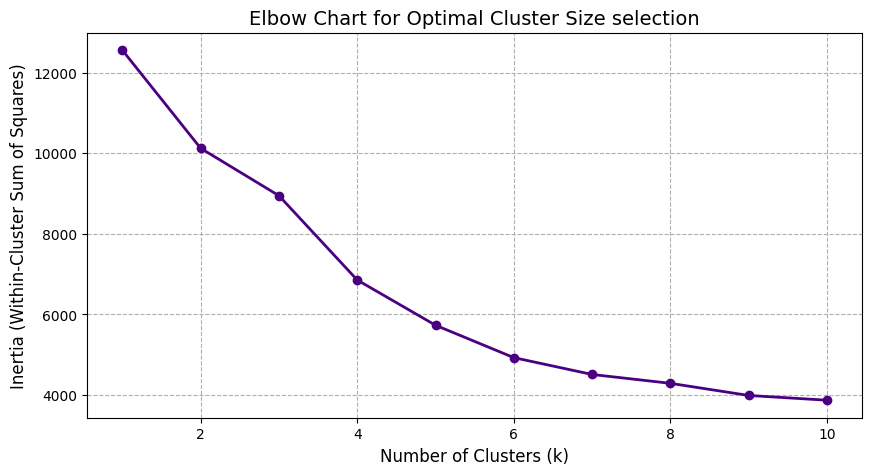

-> Based on the elbow chart bend, we choose: k = 3

[Step 3] Training K-Means model...

[Step 4] Extracting anomalies outside the 95th percentile distance...
Distance threshold at 95th percentile: 3.2424
Number of identified anomalies: 126

--- ROW NUMBERS (INDICES) OF ANOMALOUS TRANSACTIONS TO INVESTIGATE ---
[23, 26, 74, 85, 91, 146, 147, 176, 190, 231, 266, 274, 340, 344, 375, 394, 400, 414, 440, 454, 463, 475, 486, 491, 508, 535, 547, 551, 555, 588, 593, 594, 607, 614, 622, 653, 665, 669, 671, 685, 691, 693, 725, 755, 772, 792, 793, 807, 837, 850, 878, 898, 909, 916, 924, 932, 953, 961, 993, 1042, 1055, 1057, 1075, 1082, 1121, 1133, 1136, 1213, 1247, 1254, 1281, 1283, 1352, 1353, 1363, 1438, 1497, 1531, 1557, 1584, 1609, 1618, 1625, 1634, 1665, 1672, 1688, 1703, 1706, 1731, 1733, 1774, 1788, 1796, 1801, 1860, 1876, 1884, 1887, 1902, 1917, 1952, 1969, 1984, 2006, 2053, 2073, 2091, 2124, 2149, 2159, 2161, 2201, 2215, 2261, 2262, 2267, 2272, 2288, 2310, 2357, 2371, 2372, 2403, 2414, 2

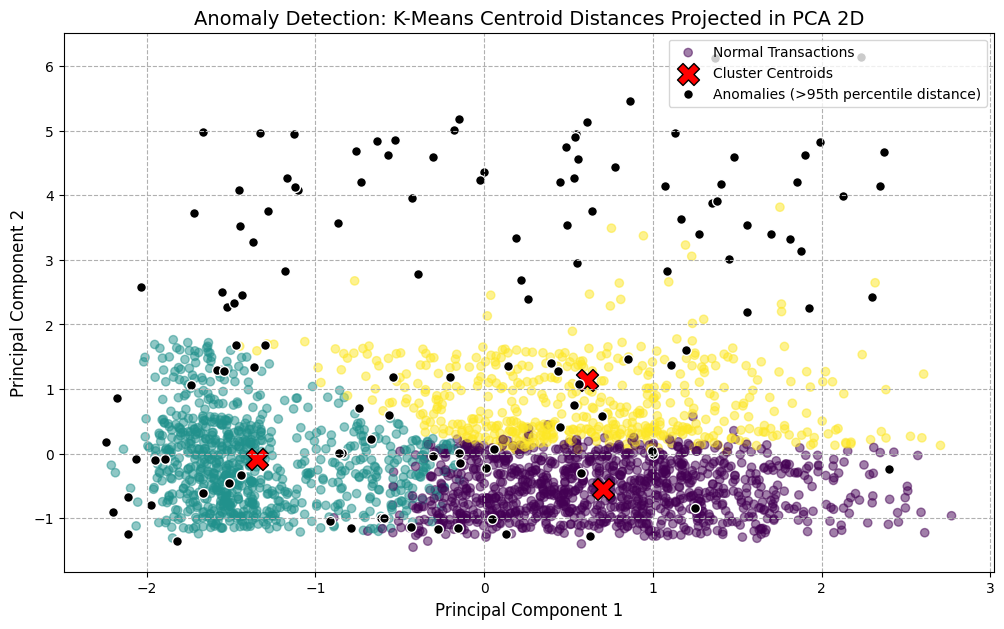

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# ======================================================================
# PLAN OF ACTION
# ======================================================================
# 1. Feature Preprocessing:
#    - Select specified numerical features: ['TransactionAmount', 'CustomerAge',
#      'TransactionDuration', 'LoginAttempts', 'AccountBalance'].
#    - Handle any potential missing values by replacing them with the column mean.
#    - Standardize the features so that they all contribute equally to distance metrics.
# 2. Elbow Method to Determine Optimal 'k':
#    - Run K-Means across a range of k (1 to 10) and calculate the inertia (sum of squared distances).
#    - Plot the Elbow chart to visually locate the 'bend' or elbow pointing to the optimal k.
# 3. K-Means Fitting and Centroid Calculations:
#    - Train a new K-Means model using the chosen optimal cluster size (k = 3).
#    - Calculate the Euclidean distance of each transaction point to its assigned cluster centroid.
# 4. Percentile Thresholding and Anomaly Detection:
#    - Find the 95th percentile threshold of distances from assigned centroids.
#    - Identify and extract transactions whose distances exceed this 95% boundary.
#    - Output the row numbers (index values) of these anomalies for investigation.
# 5. Principal Component Analysis (PCA) 2D Visualization:
#    - Transform the 5D feature space into 2D using Principal Component Analysis.
#    - Create a scatter plot visualizing normal transactions colored by cluster, the
#      centroids, and highlight the flagged anomalous points in black.
# ======================================================================

# --- Step 1: Preprocessing ---
features_to_use = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']
print("[Step 1] Loading and cleaning selected features:", features_to_use)

# Extracting the target columns from our dataset and filling NaNs with column means
X_data = df[features_to_use].copy()
X_data = X_data.fillna(X_data.mean())

# Standardizing variables to have a mean of 0 and variance of 1
scaler = StandardScaler()
X_scaled_data = scaler.fit_transform(X_data)

# --- Step 2: The Elbow Method ---
print("\n[Step 2] Computing Elbow Curve to choose optimal clusters...")
inertias_list = []
k_range = range(1, 11)
for k_num in k_range:
    temp_kmeans = KMeans(n_clusters=k_num, random_state=42)
    temp_kmeans.fit(X_scaled_data)
    inertias_list.append(temp_kmeans.inertia_)

# Plot the Elbow chart
plt.figure(figsize=(10, 5))
plt.plot(k_range, inertias_list, marker='o', linestyle='-', color='indigo', linewidth=2)
plt.title('Elbow Chart for Optimal Cluster Size selection', fontsize=14)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.grid(True, linestyle='--')
plt.show()

# Defining k=3 based on standard elbow bend observation
optimal_clusters = 3
print(f"-> Based on the elbow chart bend, we choose: k = {optimal_clusters}")

# --- Step 3: Train K-Means & Calculate Distances ---
print("\n[Step 3] Training K-Means model...")
kmeans_model = KMeans(n_clusters=optimal_clusters, random_state=42)
kmeans_model.fit(X_scaled_data)

assigned_clusters = kmeans_model.labels_
cluster_centroids = kmeans_model.cluster_centers_

# Compute distance between each point and its assigned cluster centroid
euclidean_distances = np.linalg.norm(X_scaled_data - cluster_centroids[assigned_clusters], axis=1)

# --- Step 4: Outlier Flagging & Row Indices Output ---
print("\n[Step 4] Extracting anomalies outside the 95th percentile distance...")

# Calculate the 95% distance boundary
distance_cutoff = np.percentile(euclidean_distances, 95)
anomalies_mask = euclidean_distances > distance_cutoff
anomalous_indices = np.where(anomalies_mask)[0]

print(f"Distance threshold at 95th percentile: {distance_cutoff:.4f}")
print(f"Number of identified anomalies: {len(anomalous_indices)}")
print("\n--- ROW NUMBERS (INDICES) OF ANOMALOUS TRANSACTIONS TO INVESTIGATE ---")
print(anomalous_indices.tolist())

# --- Step 5: PCA Reduced 2D Visualization ---
print("\n[Step 5] Reducing dimensions via PCA & creating plot...")
pca_obj = PCA(n_components=2)
X_pca_2d = pca_obj.fit_transform(X_scaled_data)
centroids_pca_2d = pca_obj.transform(cluster_centroids)

plt.figure(figsize=(12, 7))
# Plot typical transactions colored by their K-Means cluster
plt.scatter(X_pca_2d[~anomalies_mask, 0], X_pca_2d[~anomalies_mask, 1],
            c=assigned_clusters[~anomalies_mask], cmap='viridis', alpha=0.5, label='Normal Transactions')

# Plot centroids with a distinct red 'X'
plt.scatter(centroids_pca_2d[:, 0], centroids_pca_2d[:, 1],
            s=250, c='red', marker='X', edgecolors='black', label='Cluster Centroids')

# Highlight anomalies in high contrast black circles
plt.scatter(X_pca_2d[anomalies_mask, 0], X_pca_2d[anomalies_mask, 1],
            c='black', s=50, edgecolors='white', marker='o', label='Anomalies (>95th percentile distance)')

plt.title('Anomaly Detection: K-Means Centroid Distances Projected in PCA 2D', fontsize=14)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--')
plt.show()

Considering the results from above, calculate average transaction features for anomalies vs normal data

In [ ]:
# Create a temporary copy of the 5 key features to avoid modifying the original data
analysis_df = df[features_to_use].copy()

# Label each row as Anomaly or Normal based on the mask we computed earlier
analysis_df['Is_Anomaly'] = anomalies_mask
analysis_df['Status'] = analysis_df['Is_Anomaly'].map({True: 'Anomaly', False: 'Normal'})

# Group by status and calculate the mean for each feature
comparison_table = analysis_df.groupby('Status')[features_to_use].mean()

# Add count of records in each group
comparison_table['Transaction_Count'] = analysis_df['Status'].value_counts()

print("=== Average Feature Values: Normal vs Anomalous Transactions ===")
display(comparison_table.round(2))

=== Average Feature Values: Normal vs Anomalous Transactions ===


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Transaction_Count
Status,,,,,,
Anomaly,686.50,43.01,128.98,3.02,5030.85,126
Normal,277.06,44.76,119.15,1.02,5118.71,2386


Key Takeaways:

>Transaction Amount: Anomalous transactions are significantly higher, averaging $686.50** compared to only **$$686.50** compared to only **$277.06 for normal transactions.    

> Login Attempts: The average number of login attempts prior to anomalous transactions is 3.02, which is substantially higher than the typical 1.02 attempts observed in normal activity. This is a strong indicator of potential unauthorized access or brute-force attempts.     

>Transaction Duration: Anomalous transactions last slightly longer on average (128.98 seconds vs. 119.15 seconds).     

>Customer Age & Account Balance: These features remain relatively similar between both groups, suggesting that age and overall account size are not the primary drivers of these flagged anomalies.


## DBSCAN Clustering for Anomaly Detection 🧩

In [ ]:
# Map the cluster labels to descriptive names
label_mapping = {
    -1: 'Fraud (Outliers)',
    0: 'Normal',
    1: 'Suspicious Group 1',
    2: 'Suspicious Group 2',
    3: 'Suspicious Group 3',
    4: 'Suspicious Group 4',
}

# Select relevant features for DBSCAN
features = ['TransactionAmount', 'TransactionDuration', 'AccountBalance', 'LoginAttempts']
X = df[features].copy()

X = X.fillna(X.mean())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply DBSCAN
dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan.fit(X_scaled)

df['DBSCAN_Cluster'] = dbscan.labels_

# Map cluster labels to descriptive names
df['Cluster_Description'] = df['DBSCAN_Cluster'].map(label_mapping)

# Identify outliers (noise points) labeled as -1
potential_frauds = df[df['DBSCAN_Cluster'] == -1]
print(f"Number of potential frauds detected by DBSCAN: {len(potential_frauds)}")
display(potential_frauds.head())


Number of potential frauds detected by DBSCAN: 17


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,Cluster,DistanceToCentroid,DBSCAN_Cluster,Cluster_Description
274,TX000275,AC00454,1176.28,2023-12-20 16:08:02,Credit,Kansas City,D000476,50.202.8.53,M074,ATM,54,Engineer,174,5,323.69,2024-11-04 08:11:44,0,1.488559,-1,Fraud (Outliers)
454,TX000455,AC00264,611.11,2023-10-18 18:32:31,Debit,Detroit,D000215,141.201.46.191,M045,ATM,20,Student,282,4,919.84,2024-11-04 08:11:12,2,1.959599,-1,Fraud (Outliers)
653,TX000654,AC00423,1919.11,2023-06-27 17:48:25,Debit,Portland,D000191,207.157.126.125,M033,ATM,30,Doctor,161,1,11090.24,2024-11-04 08:10:27,0,3.828962,-1,Fraud (Outliers)
693,TX000694,AC00011,733.29,2023-03-15 18:42:16,Debit,Virginia Beach,D000618,16.51.235.240,M032,ATM,52,Doctor,94,5,10427.00,2024-11-04 08:07:12,0,0.418493,-1,Fraud (Outliers)
754,TX000755,AC00153,84.34,2023-06-08 16:27:56,Debit,Memphis,D000493,200.136.146.93,M039,Online,58,Retired,248,3,5313.97,2024-11-04 08:09:31,2,0.940290,-1,Fraud (Outliers)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Standardize features to be identical to the K-Means setup
features_to_use = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']
X_data = df[features_to_use].copy().fillna(df[features_to_use].mean())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_data)

# 2. Run DBSCAN
dbscan_model = DBSCAN(eps=1.5, min_samples=5)
dbscan_labels = dbscan_model.fit_predict(X_scaled)

# 3. Identify anomalies (-1 indicates noise/outliers in DBSCAN)
dbscan_anomalies_mask = (dbscan_labels == -1)

# 4. Extract indices
dbscan_anomalous_indices = np.where(dbscan_anomalies_mask)[0]
kmeans_anomalous_indices = anomalous_indices # From Step 4 in previous K-Means cell

# 5. Overlap analysis
overlapping_anomalies = np.intersect1d(kmeans_anomalous_indices, dbscan_anomalous_indices)

print(f"=== ANOMALY DETECTION COMPARISON ===")
print(f"K-Means Anomalies detected (95th percentile distance): {len(kmeans_anomalous_indices)}")
print(f"DBSCAN Anomalies detected (Noise points): {len(dbscan_anomalous_indices)}")
print(f"Overlapping anomalies detected by BOTH algorithms: {len(overlapping_anomalies)}")

# 6. Compare average feature values
comparison_df = df[features_to_use].copy()
comparison_df['KMeans_Anomaly'] = anomalies_mask
comparison_df['DBSCAN_Anomaly'] = dbscan_anomalies_mask

print(
    "\n=== Average Feature Values for DBSCAN Outliers ==="
)
display(comparison_df.groupby('DBSCAN_Anomaly')[features_to_use].mean().round(2))


=== ANOMALY DETECTION COMPARISON ===
K-Means Anomalies detected (95th percentile distance): 126
DBSCAN Anomalies detected (Noise points): 45
Overlapping anomalies detected by BOTH algorithms: 25

=== Average Feature Values for DBSCAN Outliers ===


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
DBSCAN_Anomaly,,,,,
False,294.66,44.57,119.00,1.09,5060.72
True,458.34,50.40,154.89,3.13,8052.10


* Plot all points colored according to their cluster labels; use black for noise/outlier points labeled `-1`.

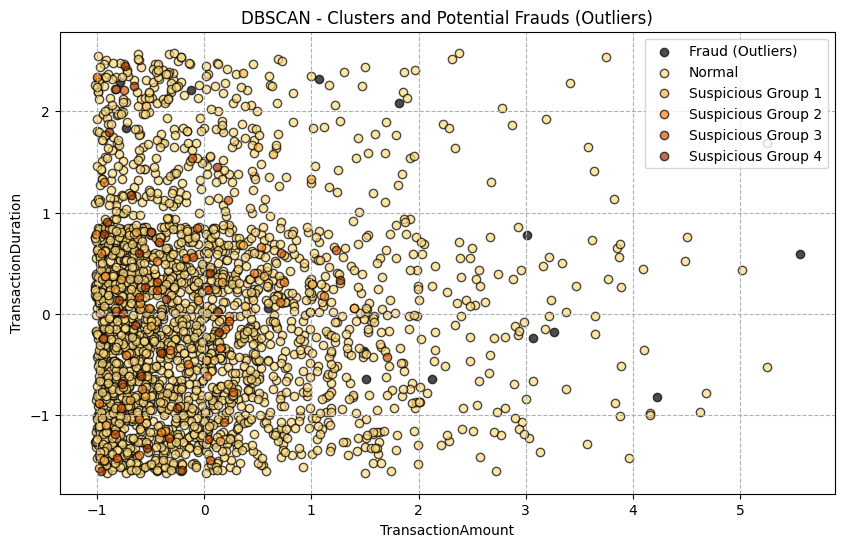

In [ ]:
# Visualize clusters and potential frauds
plt.figure(figsize=(10, 6))
unique_labels = np.unique(dbscan.labels_)

cluster_colors = sns.color_palette("YlOrBr", n_colors=len(unique_labels))

colors = []
for i, k in enumerate(unique_labels):
    if k == -1:
        colors.append([0, 0, 0, 1])  # Black for noise
    else:
        colors.append(cluster_colors[i % len(cluster_colors)])

for k, col in zip(unique_labels, colors):
    class_member_mask = (dbscan.labels_ == k)
    xy = X_scaled[class_member_mask]
    plt.scatter(xy[:, 0], xy[:, 1], color=col, edgecolor='k', alpha=0.7, label=label_mapping.get(k, f'Cluster {k}'))

plt.title('DBSCAN - Clusters and Potential Frauds (Outliers)')
plt.xlabel(features[0])  # TransactionAmount
plt.ylabel(features[1])  # TransactionDuration
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

* **Cluster Formation:** The plot shows several distinct clusters of transactions, indicating that DBSCAN has effectively grouped similar transactions together.
* **Potential Frauds (Outliers):** The black points represent the transactions identified as potential frauds (outliers) by DBSCAN. These points are scattered across the plot, suggesting that they deviate significantly from the density of any cluster.
* **Suspicious Groups:** DBSCAN has also identified several "Suspicious Groups" (colored clusters). These groups might represent transactions with specific characteristics that warrant further investigation, even though they are not considered outliers.

* **Feature Scaling:** Standardizing the features using `StandardScaler` ensures that all features have a similar scale, which is crucial for DBSCAN to work effectively.
* **Outlier Detection:** DBSCAN identifies potential frauds (outliers) as points that have low density in their local neighborhood.
* **Number of Potential Frauds:** The code identifies 17 transactions as potential frauds based on DBSCAN's outlier detection.

**Overall, the DBSCAN clustering analysis has effectively identified a set of transactions that deviate significantly from the typical transaction patterns and appear to be outliers.**


## Isolation Forest for Anomaly Detection

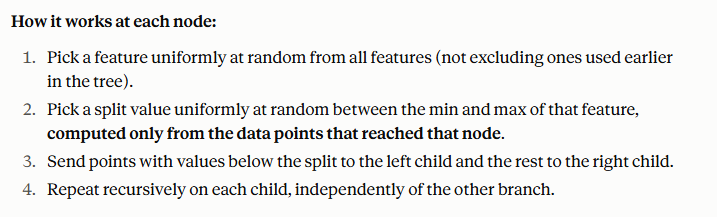

In [ ]:
# Define outlier mapping
outlier_mapping = {1: 'Normal', -1: 'Potential Fraud'}

# Select relevant features for fraud detection
features = ['TransactionAmount', 'TransactionDuration', 'AccountBalance', 'LoginAttempts']  # Modify as needed
X = df[features].copy()

X = X.fillna(X.mean())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit the Isolation Forest model
iso_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
iso_forest.fit(X_scaled)

# Predict anomalies
df['AnomalyScore'] = iso_forest.decision_function(X_scaled)
df['IsAnomaly'] = iso_forest.predict(X_scaled)

# Map results to descriptive labels
df['AnomalyLabel'] = df['IsAnomaly'].map(outlier_mapping)

# Filter out detected anomalies
potential_frauds = df[df['IsAnomaly'] == -1]
print(f"Number of potential frauds detected: {len(potential_frauds)}")
display(potential_frauds.head())

Number of potential frauds detected: 126


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,...,LoginAttempts,AccountBalance,PreviousTransactionDate,Cluster,DistanceToCentroid,DBSCAN_Cluster,Cluster_Description,AnomalyScore,IsAnomaly,AnomalyLabel
26,TX000027,AC00441,246.93,2023-04-17 16:37:01,Debit,Miami,D000046,55.154.161.250,M029,ATM,...,5,673.35,2024-11-04 08:11:38,2,0.461840,2,Suspicious Group 2,-0.075150,-1,Potential Fraud
32,TX000033,AC00060,396.45,2023-09-25 16:26:00,Debit,New York,D000621,133.67.250.163,M007,ATM,...,3,9690.15,2024-11-04 08:11:13,2,0.744993,1,Suspicious Group 1,-0.014181,-1,Potential Fraud
85,TX000086,AC00098,1340.19,2023-09-29 17:22:10,Credit,Austin,D000574,165.114.224.47,M012,Online,...,1,8654.28,2024-11-04 08:06:53,0,2.163279,0,Normal,-0.018206,-1,Potential Fraud
91,TX000092,AC00310,223.85,2023-10-02 16:36:10,Debit,Kansas City,D000481,133.223.159.151,M009,ATM,...,4,2929.91,2024-11-04 08:08:01,1,0.221557,4,Suspicious Group 4,-0.029888,-1,Potential Fraud
146,TX000147,AC00385,973.39,2023-08-30 17:23:20,Debit,Sacramento,D000292,202.194.199.70,M026,Branch,...,1,2042.22,2024-11-04 08:11:44,0,2.640557,0,Normal,-0.016904,-1,Potential Fraud


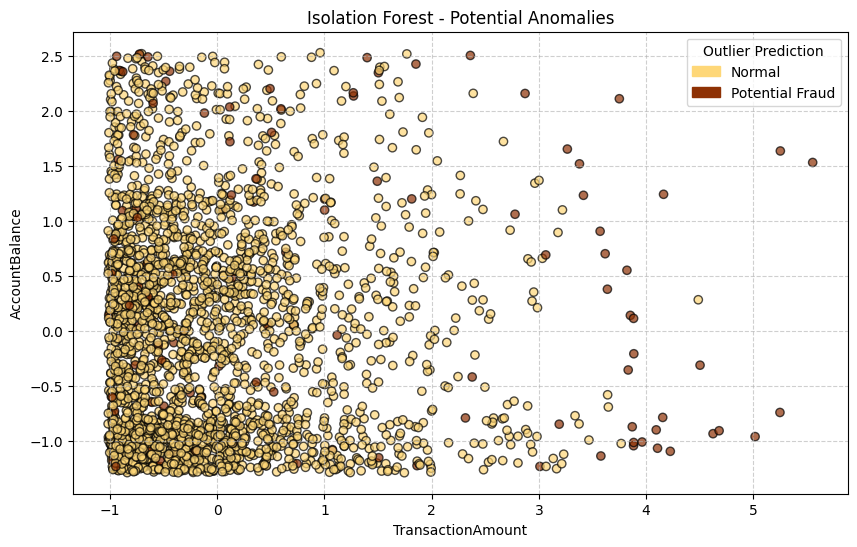

In [ ]:
cmap = plt.get_cmap('YlOrBr')
colors = np.array([cmap(0.9) if anomaly == -1 else cmap(0.3) for anomaly in df['IsAnomaly']])

# Visualize potential frauds (TransactionAmount vs AccountBalance)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    X_scaled[:, 0],  # TransactionAmount
    X_scaled[:, 2],  # AccountBalance
    c=colors,
    alpha=0.7,
    edgecolors='k',
    label='Data Points'
)

normal_patch = mpatches.Patch(color=cmap(0.3), label='Normal')
fraud_patch = mpatches.Patch(color=cmap(0.9), label='Potential Fraud')
plt.legend(handles=[normal_patch, fraud_patch], title='Outlier Prediction')

plt.title('Isolation Forest - Potential Anomalies')
plt.xlabel(features[0])
plt.ylabel(features[2])

plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

* **Anomaly Detection:** The plot effectively visualizes the Isolation Forest's ability to identify anomalies. The points colored in a darker shade represent the transactions identified as potential frauds. These points are generally scattered across the plot, indicating that they deviate significantly from the majority of the data points.

* **Normal Transactions:** The majority of data points are colored in a lighter shade, representing normal transactions. These points cluster together, suggesting that they exhibit typical transaction behavior.

* **Feature Space:** The plot shows the distribution of transactions in the "TransactionAmount" and "AccountBalance" feature space. This visualization helps to understand how these features contribute to the identification of anomalies.

* **Anomaly Score and Prediction:** The `decision_function` provides an anomaly score for each data point. The `predict` method assigns a label of 1 to normal data points and -1 to anomalies.

* **Number of Potential Frauds:** The code identifies 126 transactions as potential frauds based on the Isolation Forest model's predictions.

**Overall, the Isolation Forest has effectively identified a set of transactions that deviate significantly from the typical transaction patterns.**
